In [4]:
## import libraries
import geopandas as gpd
import xarray as xr
import numpy as np
import rioxarray as rio
import pandas as pd
import glob
import os
import re
import time
from datetime import datetime
import scipy
from tqdm import tqdm
from dask import delayed, compute
from dask.diagnostics import ProgressBar
from dask.distributed import Client, LocalCluster
import shapely
import logging

# import xesmf as xe
import xvec
import ujson
import fsspec
from kerchunk.hdf import SingleHdf5ToZarr
from kerchunk.combine import MultiZarrToZarr

# plotting
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
import math



from pathlib import Path
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

import lexcube 
import ipywidgets as widgets
from ipywidgets import interact, interactive, fixed, interact_manual

import warnings
warnings.filterwarnings("ignore")
from read_check import*

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

metref_colors = [
    (0.00, "#f1f1f1"),  # very low / near zero
    (0.08, "#556691"),
    (0.12, "#112182"),  # dark blue
    (0.22, "#135aba"),
    (0.32, "#449bf3"),  # blue
    (0.42, "#c5eefd"),  # pale blue
    (0.50, "#ffd55c"),  # yellow
    (0.60, "#ff8800"),  # orange
    (0.70, "#f11c00"),  # red
    (0.80, "#ae2716"),  # dark red
    (0.90, "#7e0007"),
    (1.00, "#510056"),  # purple / extreme
]

metref_cmap = LinearSegmentedColormap.from_list(
    "METREF",
    metref_colors,
    N=256
)

GOOD_QFLAGS = [1, 2, 3]

In [2]:
# # check the size of a file in mbs

# def file_size_mb(file_path):
#     size_bytes = os.path.getsize(file_path)
#     size_mb = size_bytes / (1024 * 1024)
#     return size_mb

# def get_folder_size_mb(folder_path):
#     total_size_bytes = 0
#     for dirpath, dirnames, filenames in os.walk(folder_path):
#         for filename in filenames:
#             file_path = os.path.join(dirpath, filename)
#             total_size_bytes += os.path.getsize(file_path)
#     total_size_mb = total_size_bytes / (1024 * 1024)
#     return total_size_mb

# file_path = "/data/sahel_cube/processed/FAPAR/kerchunk/multi/combined_refs.json"
# size_mb = file_size_mb(file_path)
# print(f"File size: {size_mb:.2f} MB")

# folder_path = "/data/sahel_cube/processed/FAPAR"
# folder_size_mb = get_folder_size_mb(folder_path)
# print(f"Folder size: {folder_size_mb:.2f} MB")

### Plotting

In [5]:
ds_halfmonth = xr.open_zarr("fapar_halfmonth.zarr", consolidated=True)
ds_halfmonth = ds_halfmonth.rio.write_crs("EPSG:4326", inplace=True)
ds_halfmonth = ds_halfmonth.rio.set_spatial_dims(x_dim="lon", y_dim="lat", inplace=True)
ds_halfmonth

<xarray.Dataset> Size: 37MB
Dimensions:      (cdr_period: 192, lat: 87, lon: 124)
Coordinates:
  * cdr_period   (cdr_period) datetime64[ns] 2kB 2011-01-01 ... 2018-12-16
    period_slot  (cdr_period) int64 2kB dask.array<chunksize=(192,), meta=np.ndarray>
  * lat          (lat) float64 696B 12.35 12.4 12.45 12.5 ... 16.55 16.6 16.65
  * lon          (lon) float64 992B -17.5 -17.45 -17.4 ... -11.45 -11.4 -11.35
    spatial_ref  int64 8B 0
Data variables:
    FAPAR_max    (cdr_period, lat, lon) float32 8MB dask.array<chunksize=(192, 87, 124), meta=np.ndarray>
    FAPAR_mean   (cdr_period, lat, lon) float32 8MB dask.array<chunksize=(192, 87, 124), meta=np.ndarray>
    FAPAR_min    (cdr_period, lat, lon) float32 8MB dask.array<chunksize=(192, 87, 124), meta=np.ndarray>
    FAPAR_std    (cdr_period, lat, lon) float32 8MB dask.array<chunksize=(192, 87, 124), meta=np.ndarray>
    n_good       (cdr_period, lat, lon) int16 4MB dask.array<chunksize=(192, 87, 124), meta=np.ndarray>
Attributes:
    temporal_aggregation:  CDR-compatible half-month
    period_definition:     01 = days 1-15; 16 = days 16-end of month

In [6]:
# load the spatial units

units = gpd.read_parquet("/data/sahel_cube/mobility_data/spatial_units_with_lat_lon.parquet")
units
# # get the bounds from the spatial units
# bounds = units.total_bounds  # (minx, miny, maxx, maxy)
# min_lon, min_lat, max_lon, max_lat = bounds
# print(f"Bounds: min_lon={min_lon}, min_lat={min_lat}, max_lon={max_lon}, max_lat={max_lat}")

,id,name,zone_category,geometry,norm_id,lon,lat
0,SEN.1.1.1-rural,Dakar-rural,rural,"MULTIPOLYGON (((-17.14005 14.57827, -17.14034 ...",sen.1.1.1,-17.187838,14.751204
1,SEN.10.1.1-rural,Mbane-rural,rural,"MULTIPOLYGON (((-15.83737 16.21078, -15.87214 ...",sen.10.1.1,-15.585999,16.227448
2,SEN.10.1.2-rural,Ndiaye Mberess-rural,rural,"MULTIPOLYGON (((-16.26705 16.0281, -16.24896 1...",sen.10.1.2,-16.093441,16.263351
3,SEN.10.2.1-rural,Cas Cas-rural,rural,"MULTIPOLYGON (((-14.37828 16.01092, -14.44253 ...",sen.10.2.1,-14.229220,16.239571
4,SEN.10.2.2-rural,Gamadji Sarre-rural,rural,"MULTIPOLYGON (((-15.03611 16.01448, -14.99439 ...",sen.10.2.2,-14.684249,16.288648
...,...,...,...,...,...,...,...
146,city-048,Thiès,urban,"MULTIPOLYGON (((-17.00244 14.80395, -17.0009 1...",city-048,-16.926520,14.790789
147,city-049,Tivaouane,urban,"MULTIPOLYGON (((-16.8533 14.93582, -16.8485 14...",city-049,-16.812656,14.965186
148,city-050,Touba,urban,"MULTIPOLYGON (((-15.92335 14.7155, -15.95312 1...",city-050,-15.871611,14.854303
149,city-052,Vélingara,urban,"MULTIPOLYGON (((-14.1644 13.10737, -14.18021 1...",city-052,-14.122209,13.141354


In [7]:
zones = units[
    ["norm_id", "zone_category", "name", "geometry"]
].copy()

# Remove invalid geometries
zones = zones.loc[
    zones.geometry.notna()
    & ~zones.geometry.is_empty
].copy()

# Optionally repair invalid polygons
zones["geometry"] = zones.geometry.make_valid()

zones = zones.loc[
    ~zones.geometry.is_empty
].reset_index(drop=True)

zones["name"] = (
    zones["name"]
    .astype(str)
    .str.strip()
)

zones["zone_category"] = (
    zones["zone_category"]
    .astype(str)
    .str.strip()
)

# Stable ID
if "norm_id" not in zones.columns:
    zones["norm_id"] = np.arange(len(zones))

print(f"Valid zones: {len(zones)}")
print("Vector CRS:", zones.crs)
print("Raster CRS:", ds_halfmonth.rio.crs)

Valid zones: 151
Vector CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "GeographicCRS", "name": "WGS 84", "datum_ensemble": {"name": "World Geodetic System 1984 ensemble", "members": [{"name": "World Geodetic System 1984 (Transit)"}, {"name": "World Geodetic System 1984 (G730)"}, {"name": "World Geodetic System 1984 (G873)"}, {"name": "World Geodetic System 1984 (G1150)"}, {"name": "World Geodetic System 1984 (G1674)"}, {"name": "World Geodetic System 1984 (G1762)"}, {"name": "World Geodetic System 1984 (G2139)"}, {"name": "World Geodetic System 1984 (G2296)"}], "ellipsoid": {"name": "WGS 84", "semi_major_axis": 6378137, "inverse_flattening": 298.257223563}, "accuracy": "2.0", "id": {"authority": "EPSG", "code": 6326}}, "coordinate_system": {"subtype": "ellipsoidal", "axis": [{"name": "Geodetic latitude", "abbreviation": "Lat", "direction": "north", "unit": "degree"}, {"name": "Geodetic longitude", "abbreviation": "Lon", "direction": "east", "unit": "deg

#### Using ´xvec´ for Zonal Stats

In [8]:
stats_list = [
    "mean",
    "min",
    "max",
    "median",
    "stdev",
    "count",
    "quantile(q=0.02)",
    "quantile(q=0.98)",
]
stats = ds_halfmonth.xvec.zonal_stats(
    zones.geometry,
    x_coords="lon",
    y_coords="lat",
    stats=stats_list,
    method="exactextract",
    name="zone",
    index=False,
)

stats

<xarray.Dataset> Size: 9MB
Dimensions:           (zonal_statistics: 8, zone: 151, cdr_period: 192)
Coordinates:
  * zonal_statistics  (zonal_statistics) <U16 512B 'mean' ... 'quantile(q=0.98)'
  * zone              (zone) geometry 1kB MULTIPOLYGON (((-17.1400547 14.5782...
  * cdr_period        (cdr_period) datetime64[ns] 2kB 2011-01-01 ... 2018-12-16
Data variables:
    FAPAR_max         (zone, zonal_statistics, cdr_period) float64 2MB 0.2649...
    FAPAR_mean        (zone, zonal_statistics, cdr_period) float64 2MB 0.2445...
    FAPAR_min         (zone, zonal_statistics, cdr_period) float64 2MB 0.2275...
    FAPAR_std         (zone, zonal_statistics, cdr_period) float64 2MB 0.0099...
    n_good            (zone, zonal_statistics, cdr_period) float64 2MB 7.306 ...
Indexes:
    zone     GeometryIndex (crs=EPSG:4326)
Attributes:
    temporal_aggregation:  CDR-compatible half-month
    period_definition:     01 = days 1-15; 16 = days 16-end of month

In [9]:
print(stats.dims)
print(stats.coords)

FrozenMappingWarningOnValuesAccess({'zonal_statistics': 8, 'zone': 151, 'cdr_period': 192})
Coordinates:
  * zonal_statistics  (zonal_statistics) <U16 512B 'mean' ... 'quantile(q=0.98)'
  * zone              (zone) geometry 1kB MULTIPOLYGON (((-17.1400547 14.5782...
  * cdr_period        (cdr_period) datetime64[ns] 2kB 2011-01-01 ... 2018-12-16


In [10]:
stats = stats.assign_coords(
    norm_id=(
        "zone",
        zones["norm_id"].to_numpy()
    ),
    city_name=(
        "zone",
        zones["name"].to_numpy()
    ),
    zone_cat=(
        "zone",
        zones["zone_category"].to_numpy()
    ),
)

In [9]:
# stats = stats.assign_coords(
#     geometry=(
#         "zone",
#         zones.geometry.to_numpy()
#     )
# )
# stats

In [11]:
stats

<xarray.Dataset> Size: 9MB
Dimensions:           (zone: 151, zonal_statistics: 8, cdr_period: 192)
Coordinates:
  * zone              (zone) geometry 1kB MULTIPOLYGON (((-17.1400547 14.5782...
    norm_id           (zone) object 1kB 'sen.1.1.1' 'sen.10.1.1' ... 'city-054'
    city_name         (zone) object 1kB 'Dakar-rural' ... 'Ziguinchor'
    zone_cat          (zone) object 1kB 'rural' 'rural' ... 'urban' 'urban'
  * zonal_statistics  (zonal_statistics) <U16 512B 'mean' ... 'quantile(q=0.98)'
  * cdr_period        (cdr_period) datetime64[ns] 2kB 2011-01-01 ... 2018-12-16
Data variables:
    FAPAR_max         (zone, zonal_statistics, cdr_period) float64 2MB 0.2649...
    FAPAR_mean        (zone, zonal_statistics, cdr_period) float64 2MB 0.2445...
    FAPAR_min         (zone, zonal_statistics, cdr_period) float64 2MB 0.2275...
    FAPAR_std         (zone, zonal_statistics, cdr_period) float64 2MB 0.0099...
    n_good            (zone, zonal_statistics, cdr_period) float64 2MB 7.306 ...
Indexes:
    zone     GeometryIndex (crs=EPSG:4326)
Attributes:
    temporal_aggregation:  CDR-compatible half-month
    period_definition:     01 = days 1-15; 16 = days 16-end of month

In [12]:
%reload_ext autoreload
%autoreload 2
from plot_zonal_maps import *

In [28]:
# fig, _, _ = plot_zonal_maps(
#     stats,
#     variable="FAPAR_mean",
#     statistic="mean",
#     cmap="RdBu_r",
# )

,norm_spatial_id_origin,origin_name,origin_type,HalfMonthIndex,date,subset_type,days_span,norm_spatial_id_destination,destination_name,destination_type,flow_type,N_depart,N_return,N_migrants,pop_observed_depart,pop_observed_return,rate_depart,rate_return,dest_label
0,city-001,Bambey,urban,20130201,2013-02-01,A,30days,city-002,Bignona,urban,urban → urban,0.000000,0.000000,0.000000,54515.947210,54515.947210,0.000000,0.000000,bignona__city_002
1,city-001,Bambey,urban,20130201,2013-02-01,A,30days,city-004,Dagana,urban,urban → urban,0.000000,11.452930,11.431316,54515.947210,54515.947210,0.000000,0.000210,dagana__city_004
2,city-001,Bambey,urban,20130201,2013-02-01,A,30days,city-005,Dahra Djoloff,urban,urban → urban,0.000000,0.000000,0.000000,54515.947210,54515.947210,0.000000,0.000000,dahra_djoloff__city_005
3,city-001,Bambey,urban,20130201,2013-02-01,A,30days,city-006,Dakar,urban,urban → urban,217.195009,377.946693,823.054770,54515.947210,54515.947210,0.003984,0.006933,dakar__city_006
4,city-001,Bambey,urban,20130201,2013-02-01,A,30days,city-007,Darou Mousty,urban,urban → urban,0.000000,0.000000,0.000000,54515.947210,54515.947210,0.000000,0.000000,darou_mousty__city_007
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1449595,sen.9.3.1,Velingara-rural,rural,20151116,2015-11-16,A,30days,sen.8.3.4,Sakal-rural,rural,rural → rural,0.000000,0.000000,0.000000,31051.919546,31051.919546,0.000000,0.000000,sakal_rural__sen_8_3_4
1449596,sen.9.3.1,Velingara-rural,rural,20151116,2015-11-16,A,30days,sen.9.1.1,Orkadiere-rural,rural,rural → rural,0.000000,31.605007,15.850903,31051.919546,31051.919546,0.000000,0.001018,orkadiere_rural__sen_9_1_1
1449597,sen.9.3.1,Velingara-rural,rural,20151116,2015-11-16,A,30days,sen.9.1.2,Ouro Sidy-rural,rural,rural → rural,15.858999,15.802504,15.850903,31051.919546,31051.919546,0.000511,0.000509,ouro_sidy_rural__sen_9_1_2
1449598,sen.9.3.1,Velingara-rural,rural,20151116,2015-11-16,A,30days,sen.9.2.1,Agnam Civol-rural,rural,rural → rural,15.858999,15.802504,174.359936,31051.919546,31051.919546,0.000511,0.000509,agnam_civol_rural__sen_9_2_1


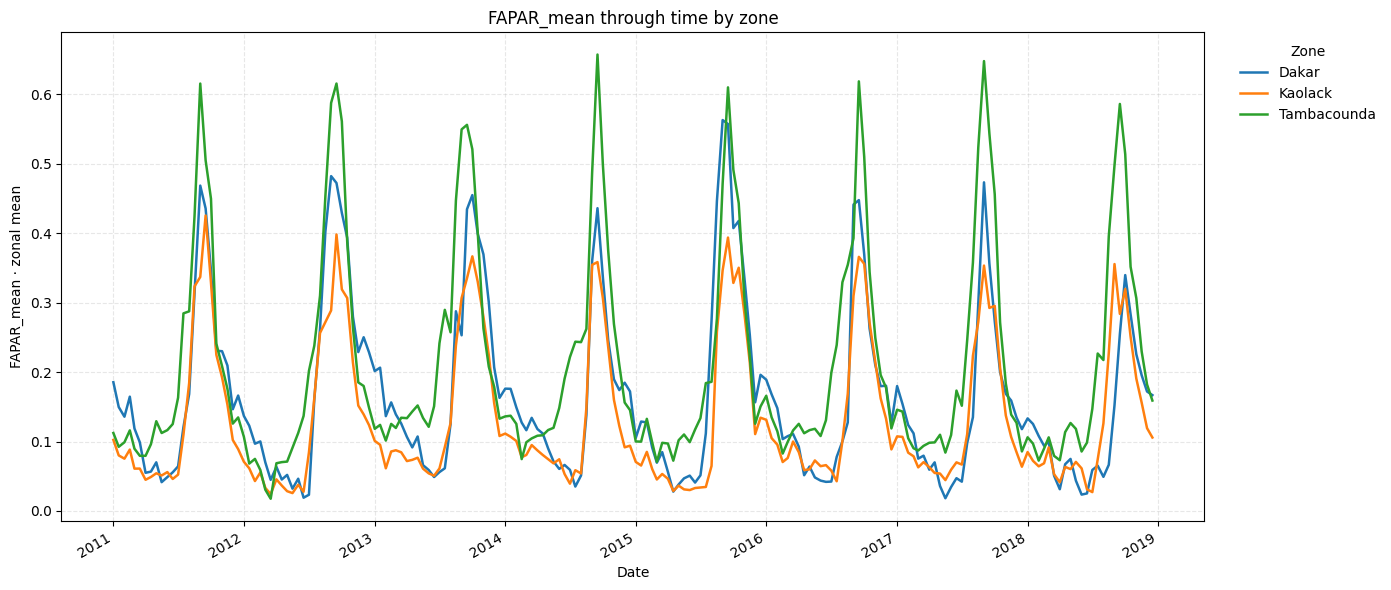

In [16]:
plot_zone_timeseries(
    stats,
    variable="FAPAR_mean",
    statistic="mean",
    cities=[
        "Dakar",
        "Kaolack",
        "Tambacounda",
    ],
)

# plot mobility data as well alongside

mobility_data = pd.read_parquet("/data/sahel_cube/mobility_data/processed_mobility_tables/long_od_time_weighted_A_30days.parquet")
mobility_data

In [21]:
selected_regions = [
    "Dakar",
    "Kaolack",
    "Tambacounda",
]

# Keep the mobility data within the selected date range and regions
mobility = mobility_data.copy()
mobility["date"] = pd.to_datetime(mobility["date"])

mobility = mobility[
    mobility["origin_name"].isin(selected_regions)
].copy()

# Aggregate origin-to-destination flows for each selected origin and date
mobility_ts = (
    mobility
    .groupby(["origin_name", "date"], as_index=False)[
        ["N_depart", "N_return", "N_migrants"]
    ]
    .sum()
)


In [22]:
mobility_ts

,origin_name,date,N_depart,N_return,N_migrants
0,Dakar,2013-02-01,8015.740282,14448.690455,54867.237914
1,Dakar,2013-02-16,5426.863114,11217.490370,46906.086953
2,Dakar,2013-03-01,6577.786910,12168.019936,42588.683913
3,Dakar,2013-03-16,6404.312383,13584.697070,35759.723352
4,Dakar,2013-04-01,10063.354163,9915.453382,33473.425508
...,...,...,...,...,...
187,Tambacounda,2015-09-16,2055.494523,2393.512873,8747.371346
188,Tambacounda,2015-10-01,2054.595269,2377.652715,8812.993571
189,Tambacounda,2015-10-16,1680.680900,2342.382820,8633.074459
190,Tambacounda,2015-11-01,1867.179519,1434.119121,8283.860035


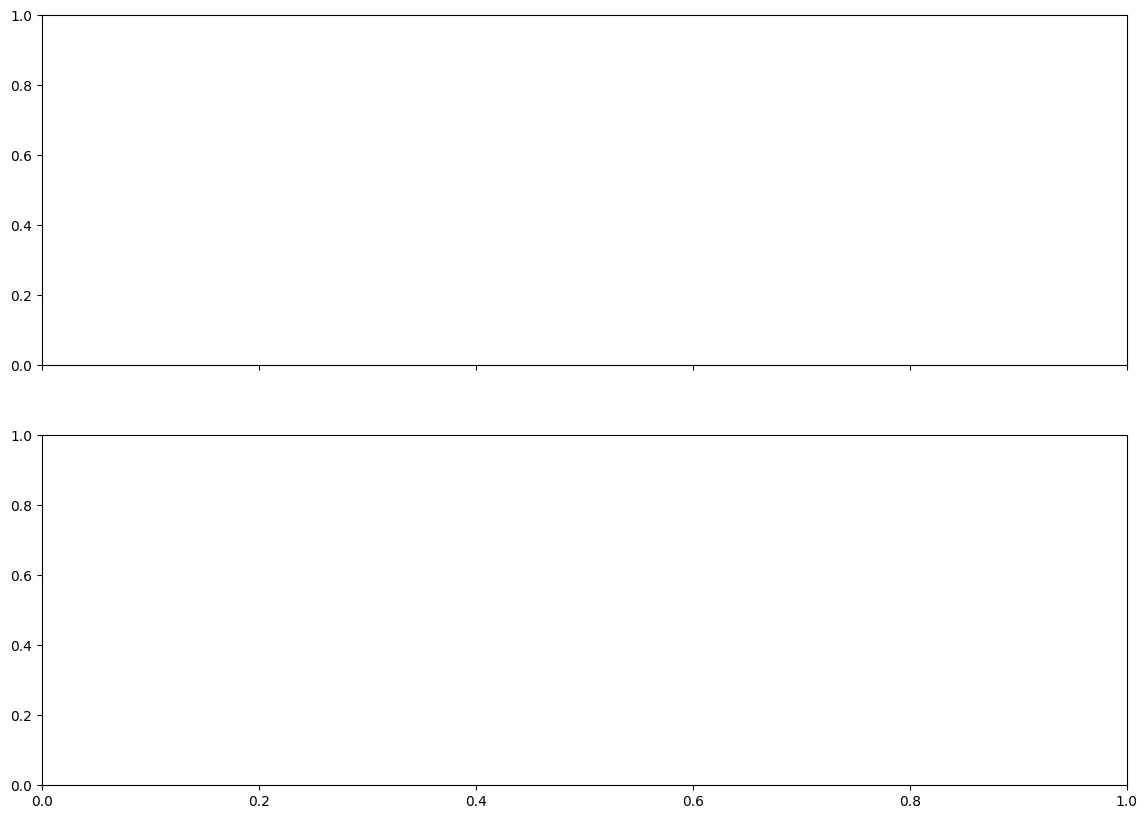

In [26]:
fig, (ax_climate, ax_mobility) = plt.subplots(
    2,
    1,
    figsize=(14, 10),
    sharex=True,
)

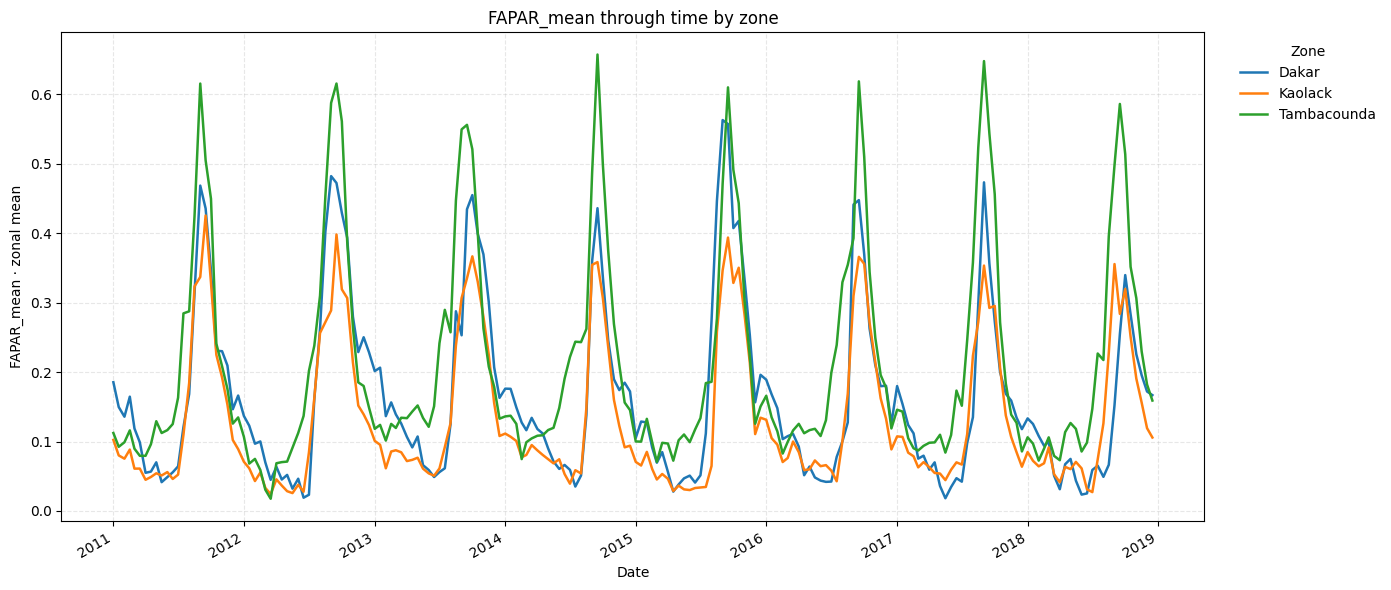

In [25]:
climate_fig, climate_ax, climate_source = plot_zone_timeseries(
    stats,
    variable="FAPAR_mean",
    statistic="mean",
    cities=selected_regions,
    figsize=(14, 6),
)

# Copy climate lines to the combined figure
for line in climate_ax.lines:
    ax_climate.plot(
        line.get_xdata(),
        line.get_ydata(),
        label=line.get_label(),
        linewidth=line.get_linewidth(),
        linestyle=line.get_linestyle(),
        color=line.get_color(),
    )

ax_climate.set_ylabel("FAPAR")
ax_climate.set_title("Climate and mobility for selected regions")
ax_climate.legend(
    title="Region",
    frameon=False,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)
ax_climate.grid(alpha=0.3, linestyle="--")

# Mobility panel
for region in selected_regions:
    region_mobility = mobility_ts[
        mobility_ts["origin_name"] == region
    ].sort_values("date")

    ax_mobility.plot(
        region_mobility["date"],
        region_mobility["N_depart"],
        label=f"{region} outbound",
        linewidth=1.8,
    )

    ax_mobility.plot(
        region_mobility["date"],
        region_mobility["N_return"],
        linestyle="--",
        linewidth=1.5,
        label=f"{region} return",
    )

ax_mobility.set_xlabel("Date")
ax_mobility.set_ylabel("Aggregated mobility rate")
ax_mobility.set_title("Mobility by selected region")
ax_mobility.grid(alpha=0.3, linestyle="--")
ax_mobility.legend(
    frameon=False,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

fig.autofmt_xdate()
fig.tight_layout()
plt.show()

# Close the temporary climate-only figure created by plot_zone_timeseries
plt.close(climate_fig)

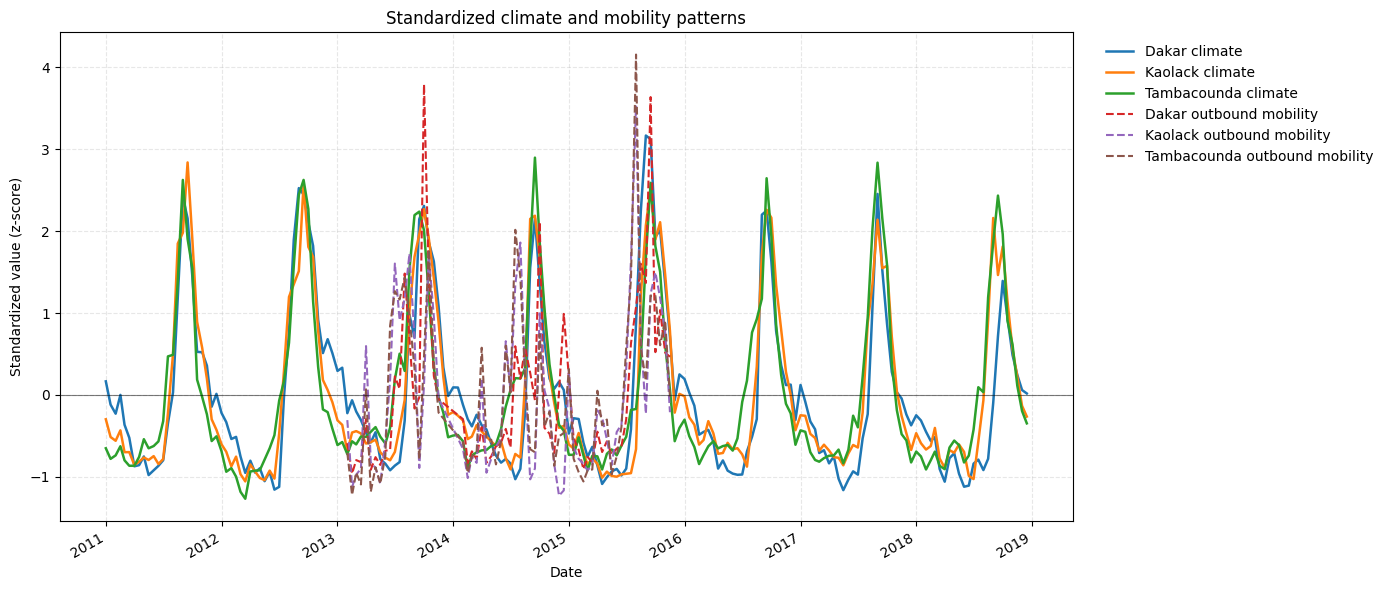

In [28]:
def zscore(series):
    return (series - series.mean()) / series.std()

fig, ax = plt.subplots(figsize=(14, 6))

# Climate
for line in climate_ax.lines:
    values = pd.Series(line.get_ydata())
    ax.plot(
        line.get_xdata(),
        zscore(values),
        label=f"{line.get_label()} climate",
        linewidth=1.8,
    )

# Mobility
for region in selected_regions:
    region_mobility = mobility_ts[
        mobility_ts["origin_name"] == region
    ].sort_values("date")

    ax.plot(
        region_mobility["date"],
        zscore(region_mobility["N_depart"]),
        linestyle="--",
        label=f"{region} outbound mobility",
    )

ax.axhline(0, color="black", linewidth=0.8, alpha=0.5)
ax.set_xlabel("Date")
ax.set_ylabel("Standardized value (z-score)")
ax.set_title("Standardized climate and mobility patterns")
ax.grid(alpha=0.3, linestyle="--")
ax.legend(frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")

fig.autofmt_xdate()
fig.tight_layout()
plt.show()

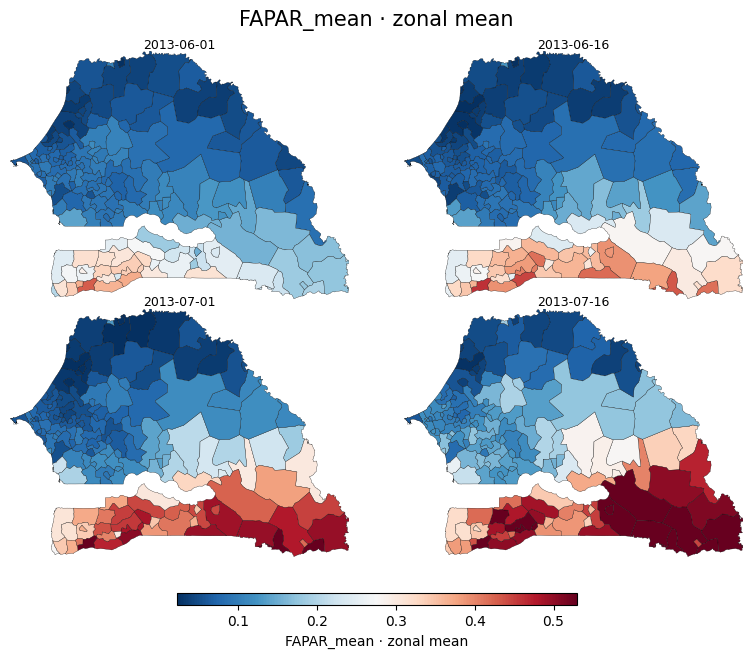

In [30]:
fig, axes, data_plot = plot_metref_maps(
    stats,
    variable="FAPAR_mean",
    statistic="mean",
    metref_cmap="RdBu_r",
    periods=[
        "2013-06-01",
        "2013-06-16",
        "2013-07-01",
        "2013-07-16",
    ],
    col_wrap=2,
    robust=True,
)

(<Figure size 1600x960 with 11 Axes>,
 array([[<Axes: title={'center': '2011-01-01'}, ylabel='Geodetic latitude\n[degree]'>,
         <Axes: title={'center': '2011-01-16'}>,
         <Axes: title={'center': '2011-02-01'}>,
         <Axes: title={'center': '2011-02-16'}>],
        [<Axes: title={'center': '2011-03-01'}, ylabel='Geodetic latitude\n[degree]'>,
         <Axes: title={'center': '2011-03-16'}>,
         <Axes: title={'center': '2011-04-01'}>,
         <Axes: title={'center': '2011-04-16'}>],
        [<Axes: title={'center': '2011-05-01'}, xlabel='Geodetic longitude\n[degree]', ylabel='Geodetic latitude\n[degree]'>,
         <Axes: title={'center': '2011-05-16'}, xlabel='Geodetic longitude\n[degree]'>,
         <Axes: xlabel='Geodetic longitude\n[degree]'>,
         <Axes: xlabel='Geodetic longitude\n[degree]'>]], dtype=object),
 <xarray.DataArray 'FAPAR_mean' (zone: 151, cdr_period: 10)> Size: 12kB
 array([[0.24447405, 0.21058953, 0.19344012, ..., 0.10199769, 0.11638135,
   

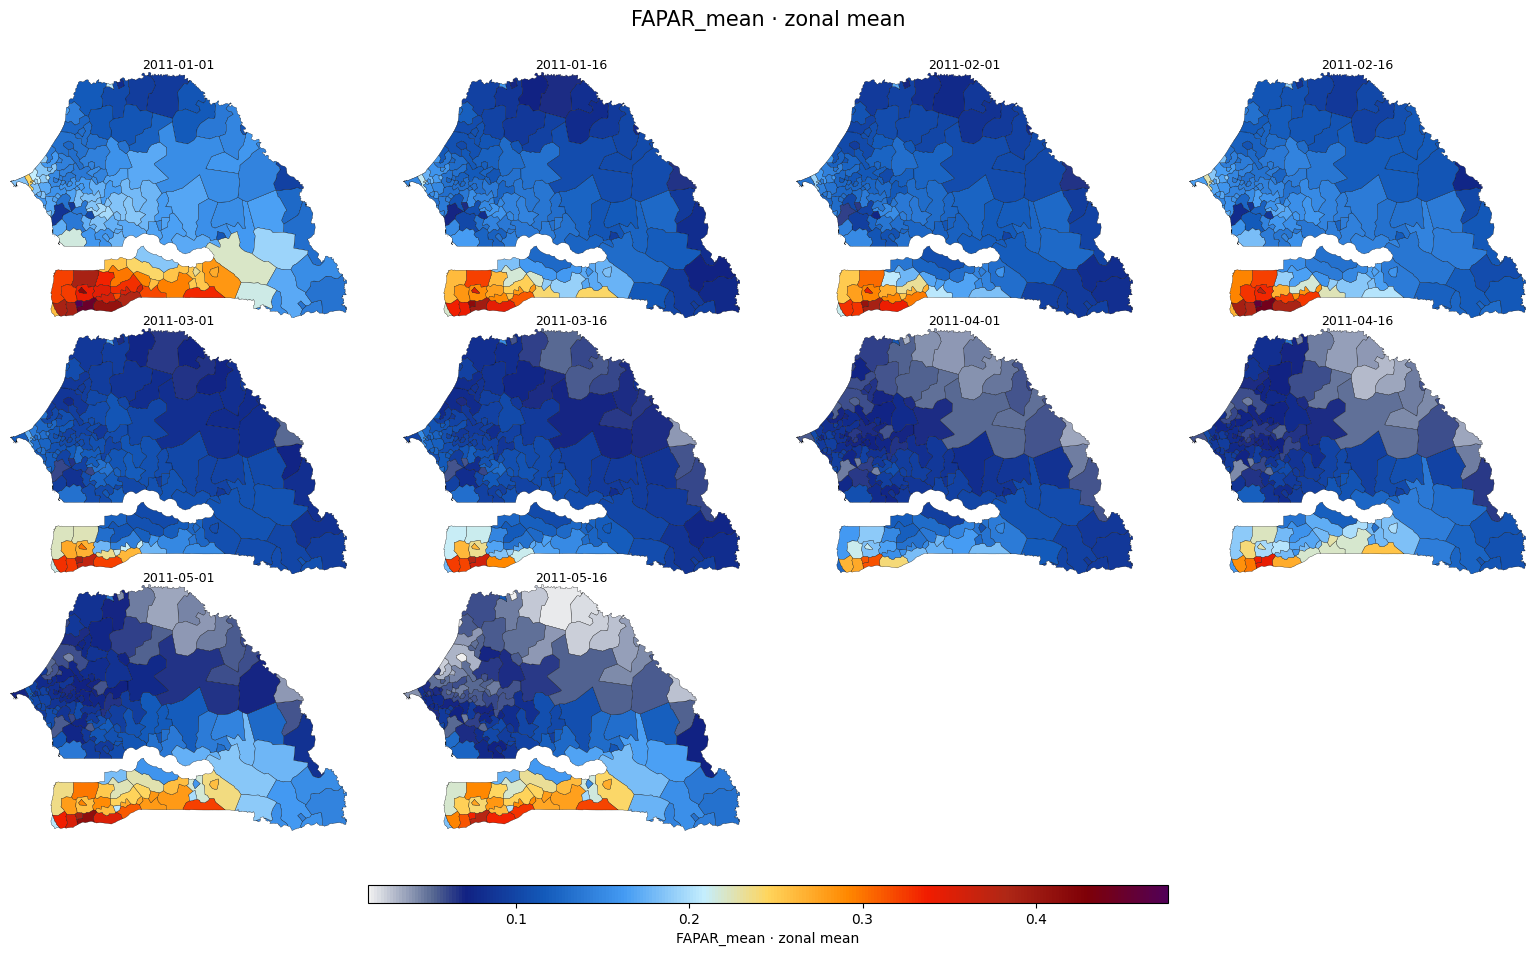

In [15]:
plot_metref_maps(
    stats,
    variable="FAPAR_mean",
    statistic="mean",
    metref_cmap=metref_cmap,
    time_index=slice(0, 10),
)

In [46]:
# fig,_,_=plot_metref_maps(
#     stats,
#     variable="FAPAR_mean",
#     statistic="stdev",
#     metref_cmap=metref_cmap,
#     time_index=slice(10, 11),
# )
# fig.savefig("metref_maps_st_dev.png", dpi=500, bbox_inches="tight")

In [44]:
# fig,_,_=plot_metref_maps(
#     stats,
#     variable="FAPAR_mean",
#     statistic="mean",
#     metref_cmap=metref_cmap,
#     time_index=slice(10, 11),
# )

# fig.savefig("metref_maps.png", dpi=500, bbox_inches="tight"
# )

In [45]:

# fig,_,_=plot_metref_maps(
#     stats,
#     variable="FAPAR_mean",
#     statistic="quantile(q=0.98)",
#     metref_cmap=metref_cmap,
#     time_index=slice(0, 11),
# )
# fig.savefig("metref_maps_quantile_98.png", dpi=500, bbox_inches="tight"
# )

### Time Series Analysis

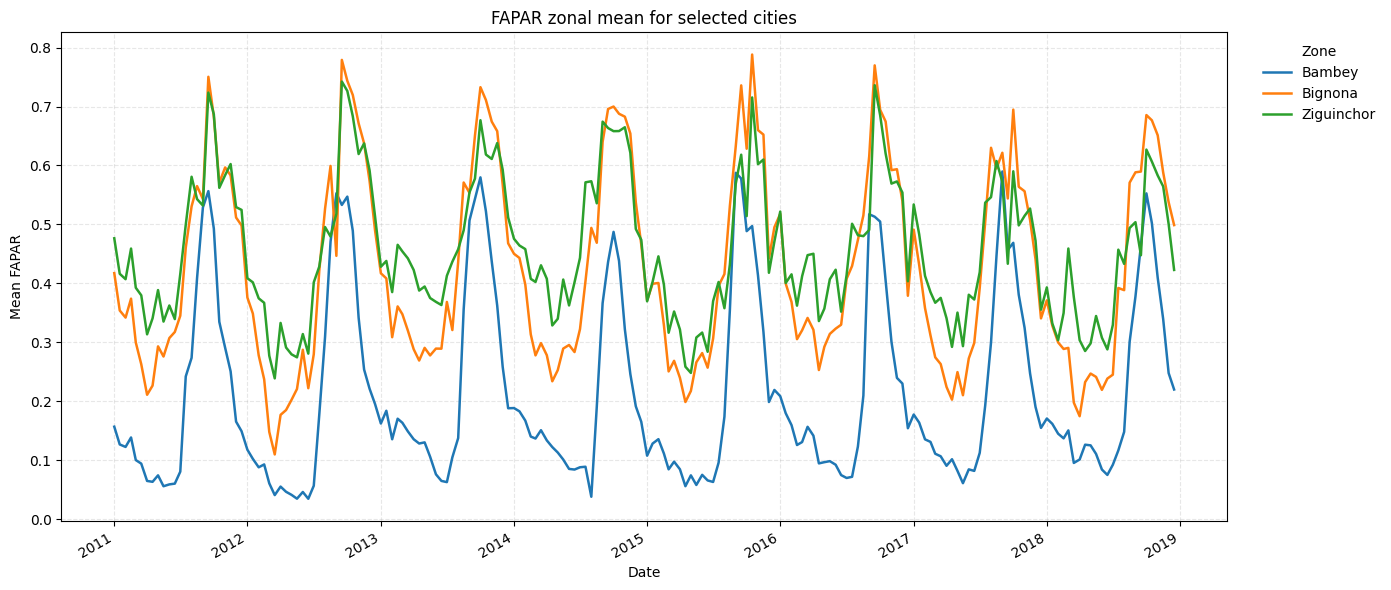

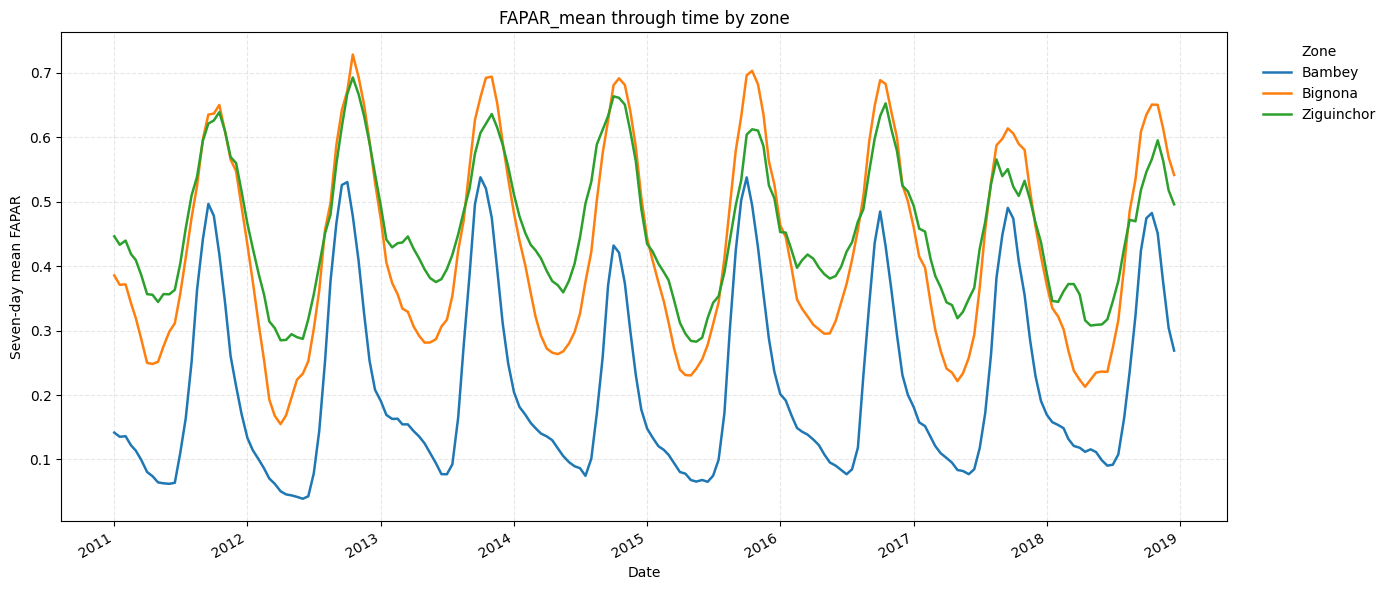

In [16]:
fig, ax, selected = plot_city_timeseries(
    stats,
    variable="FAPAR_mean",
    cities=[
        "Bambey",
        "Bignona",
        "Ziguinchor",
    ],
    start="2011-01-01",
    end="2018-12-16",
    ylabel="Mean FAPAR",
    title="FAPAR zonal mean for selected cities",
)

# fig, ax, selected = plot_city_timeseries(
#     urban_stats,
#     variable="METREF",
#     cities=[
#         "Bambey",
#         "Bignona",
#         "Ziguinchor",
#     ],
#     marker="o",
# )
fig, ax, selected = plot_city_timeseries(
    stats,
    variable="FAPAR_mean",
    cities=[
        "Bambey",
        "Bignona",
        "Ziguinchor",
    ],
    rolling_window=4,
    ylabel="Seven-day mean FAPAR",
)

the pattern in FAPAR time series corresponds quite well to the **general seasonal climate and vegetation cycle of Senegal**, especially considering the north–south climatic gradient.

The main signal is exactly what we would expect:

- **Dry season: roughly November–May** → vegetation activity declines and FAPAR reaches its minimum, typically around **March–May**.
- **Rainy season: roughly June–October** → vegetation rapidly greens up after the onset of rainfall.
- **Peak vegetation: approximately August–October** → FAPAR reaches its annual maximum.
- After rainfall stops, FAPAR decreases again through **October–December**.

three zones also behave sensibly geographically. **Bambey** has the lowest FAPAR and the strongest seasonal amplitude, which fits its drier central-western/Sahelian setting. **Bignona and Ziguinchor**, in the wetter Casamance region of southern Senegal, maintain considerably higher vegetation activity, including during the dry season, and reach FAPAR values around 0.55–0.65 during the wet season.

One particularly encouraging feature is that the curves are not identical:

> **Bambey:** ~0.05–0.45  
> **Bignona:** ~0.20–0.65  
> **Ziguinchor:** ~0.30–0.63

That spatial ordering broadly reflects Senegal's **north/central → south rainfall and vegetation gradient**.

There is one interesting detail in the plot: **Ziguinchor often has a higher dry-season baseline than Bignona, while Bignona sometimes has slightly higher wet-season peaks.** That is completely plausible because FAPAR reflects actual vegetation cover and land-cover composition, not rainfall alone. Cropland, woodland, mangroves, forest, fallow land, and agricultural phenology can alter the signal.

A good caption can be:

> **“The FAPAR time series reproduces the expected seasonal vegetation cycle and regional climatic gradient across selected Senegalese zones.”**

In [2]:
# import pandas as pd
# import matplotlib.pyplot as plt
# from statsmodels.tsa.seasonal import STL


# def decompose_zone(
#     df,
#     variable="FAPAR_mean",
#     zone_col="name",
#     zone="Bambey",
#     time_col="time",
#     period=24,
# ):
#     """
#     STL decomposition of a 15-day zonal climate time series.

#     Returns
#     -------
#     DataFrame with:
#         observed
#         trend
#         seasonal
#         residual
#     """

#     d = (
#         df.loc[df[zone_col] == zone, [time_col, variable]]
#         .copy()
#         .dropna()
#         .sort_values(time_col)
#     )

#     d[time_col] = pd.to_datetime(d[time_col])
#     d = d.set_index(time_col)

#     # STL decomposition
#     stl = STL(
#         d[variable],
#         period=period,
#         robust=True
#     )

#     result = stl.fit()

#     out = pd.DataFrame({
#         "observed": d[variable],
#         "trend": result.trend,
#         "seasonal": result.seasonal,
#         "residual": result.resid,
#     })

#     return out